# Assignment 2
## Hien Bui

In [25]:
import numpy as np
import matplotlib.pyplot as plt

### 1. Numpy Arrays
Create an array with `np.arange()` and `.reshape()` it into a 2-d array

In [4]:
range = np.arange(20)
range = range.reshape(4, 5)
print(range)

[[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]
 [15 16 17 18 19]]


Print its `ndim`, `shape`, and `dtype`

In [6]:
print(range.ndim)
print(range.shape)
print(range.dtype)

2
(4, 5)
int64


Compute its `.sum()` with `axis=0` and with `axis=1`. In a Markdown cell, explain the difference between the two results.

In [7]:
print(range.sum(axis=0))
print(range.sum(axis=1))

[30 34 38 42 46]
[10 35 60 85]


For a mxn matrix, `.sum(axis=0)` gives us a 1xn matrix in which the nth cell is the sum of values in the matrix's nth column. Alternatively, '.sum(axis=1)` gives us a 1xm matrix in which the mth cell is the sum of values in the matrix's mth row.

Multiply your 2-d array by a 1-d array to demonstrate broadcasting

In [10]:
d = np.arange(5)
print(range * d)

[[ 0  1  4  9 16]
 [ 0  6 14 24 36]
 [ 0 11 24 39 56]
 [ 0 16 34 54 76]]


### 2. A simulation
Create a seeded random number generator with `np.random.default_rng()`

In [14]:
rng = np.random.default_rng(30)
rng.random()

0.2357988048125328

Use `rng.choice()` to draw 5 random walks of 500 steps each, of `-1` or `1`, as a single array with `size=(5, 500)`

In [16]:
choice = rng.choice([-1, 1], size=(5, 500))
print(choice)

[[ 1 -1 -1 ...  1 -1  1]
 [ 1 -1  1 ...  1  1  1]
 [-1  1  1 ... -1  1  1]
 [-1  1 -1 ...  1  1  1]
 [-1 -1 -1 ... -1 -1  1]]


Use `np.cumsum()` with the right `axis` to turn the steps into positions

In [19]:
pos = np.cumsum(choice, axis=1)
print(pos)

[[  1   0  -1 ...  18  17  18]
 [  1   0   1 ... -18 -17 -16]
 [ -1   0   1 ...  16  17  18]
 [ -1   0  -1 ...  -2  -1   0]
 [ -1  -2  -3 ...  12  11  12]]


In a Markdown cell, answer: what is the `shape` of your array of positions, and what does each row represent?

In [21]:
print(pos.shape)

(5, 500)


Each row represents a walk (there are 5 of them) and the nth cell in each row represents the position after the nth step (e.g. the last cell in each row is the final position). 

### 3. Building a plot in Matplotlib

Using `fig, ax = plt.subplots()`:

- Plot all 5 random walks on a single Axes
- Give each line a unique color and linestyle, and a `label`
- Add a horizontal reference line at 0 with `ax.axhline()`
- Add a title, axis labels, and a legend

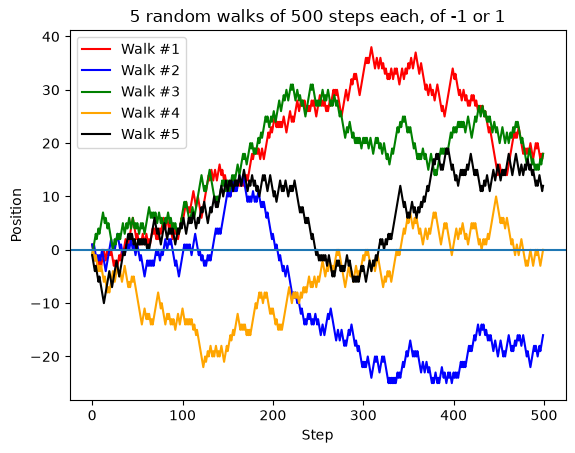

In [29]:
fig, ax = plt.subplots()
ax.plot(pos[0], color='red', label='Walk #1')
ax.plot(pos[1], color='blue', label='Walk #2')
ax.plot(pos[2], color='green', label='Walk #3')
ax.plot(pos[3], color='orange', label='Walk #4')
ax.plot(pos[4], color='black', label='Walk #5')
ax.axhline()
ax.set_xlabel('Step') 
ax.set_ylabel('Position')  
ax.set_title("5 random walks of 500 steps each, of -1 or 1") 
ax.legend()  

### 4. Building Subplots in Matplotlib
Simulate 1,000 random walks of 500 steps each, and compute the final position of each walk
- Create a figure with two subplots side by side:
  - On the left, your plot of 5 random walks from Section 3
  - On the right, a histogram of the 1,000 final positions
- Add a title to each subplot and to the figure with `fig.suptitle()`
- Save your figure as `random_walks.png` with `fig.savefig()`

In [38]:
walks = rng.choice([-1, 1], size=(1000, 500))
final = walks.sum(axis=1)

Text(0.5, 1.0, 'Histogram of 1000 final positions')

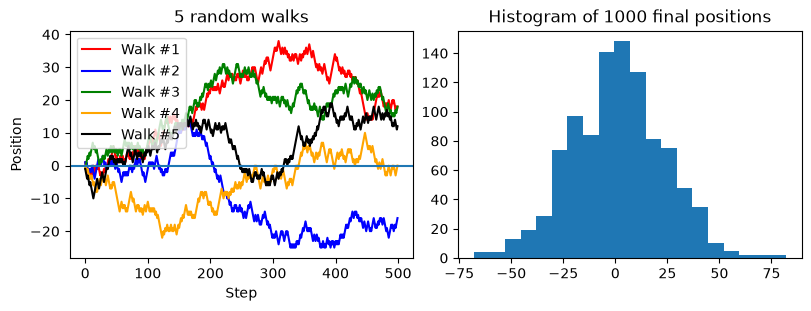

In [39]:
fig, axes = plt.subplots(1, 2, figsize = (8, 3), layout= 'constrained')
axes[0].plot(pos[0], color='red', label='Walk #1')
axes[0].plot(pos[1], color='blue', label='Walk #2')
axes[0].plot(pos[2], color='green', label='Walk #3')
axes[0].plot(pos[3], color='orange', label='Walk #4')
axes[0].plot(pos[4], color='black', label='Walk #5')
axes[0].axhline()
axes[0].set_xlabel('Step') 
axes[0].set_ylabel('Position')  
axes[0].set_title("5 random walks") 
axes[0].legend()  
axes[1].hist(final, bins=20)
axes[1].set_title('Histogram of 1000 final positions')

In [36]:
fig.savefig('random_walks.png', dpi=150)